# Lecture 22 notebook: a market that reacts

This notebook replays Lecture 22. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process, so that memory is freed after every step.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | One order, two replays: the key chart | §1 |
| 2 | The laboratory market: its checks, the ten steps, calm to cascade | §2 |
| 3 | The reaction on our data, in sample | §3 |
| 4 | Does the hybrid replay tell the truth? The tests | §4 |
| 5 | Close to the tipping point | §5 |
| 6 | A test of your own: why runs cannot be added up | §7.2 |

**Three switches, all off by default.** Heavy steps run only when you switch them on in §0.

* **Off (default): the figures and tables only.** All figures are redrawn from the small results shipped in `results/` and match the lecture's; the laboratory market's hand-case checks are run, and the numbers the lecture quotes are printed from the results. No market data is needed; it takes a few minutes.
* **`RUN_CHECK = True`: one day of Bybit data.** The order table and the pass over the book are rebuilt for `CHECK_DAY` and five of its numbers are compared with the lecture's. It needs the Parquet tables of Lecture 18 for that day (`BYBIT_ROOT`, default `data/bybit` at the top of the repository), Lecture 19's book state (built if missing) and the Binance trades of Lecture 20 (`BINANCE_ROOT`). About five minutes once the book state exists.
* **`RUN_SIM = True`: the laboratory market.** Steps 3 to 10 are simulated again. Each step takes from a few minutes to about half an hour; the whole set a few hours, on one core.
* **`RUN_ALL = True`: everything on Bybit.** The order tables and the book pass for every day in the data folder (about two minutes a day for the book), the layers in sample, the key chart, the tests out of sample and their charts. A job of a few hours; days already done are skipped.

With any switch on, results go to `L22_OUT/results` (default `BYBIT_ROOT/interim/l22/results`), starting from a copy of the shipped ones, so the lecture's own results are never overwritten; figures are saved in `figures/` as `nb_*`.

## 0. Settings

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
OTHER = {19: HERE.parent / "19-statistics-of-the-book" / "scripts", 22: SCRIPTS}
sys.path[:0] = [str(SCRIPTS)]
import l22 as L
CHECK_DAY = "2025-10-01"                                                   # the day rebuilt by RUN_CHECK
RUN_CHECK = False                                                          # True: rebuild CHECK_DAY from Bybit data (about five minutes)
RUN_SIM = False                                                            # True: simulate the laboratory market again (a few hours)
RUN_ALL = False                                                            # True: recompute everything on Bybit data (a few hours)

SHIPPED = HERE / "results"; WORK = L.OUT / "results"
if RUN_CHECK or RUN_SIM or RUN_ALL:                                       # recomputed results never overwrite the shipped ones
    WORK.mkdir(parents=True, exist_ok=True)
    for f in SHIPPED.glob("*.json"):
        if not (WORK / f.name).exists(): shutil.copy(f, WORK / f.name)
RES = WORK if (RUN_CHECK or RUN_SIM or RUN_ALL) else SHIPPED
pl.Config.set_tbl_rows(50); pl.Config.set_fmt_str_lengths(80); pl.Config.set_tbl_width_chars(200); pl.Config.set_tbl_cols(20)
DAYS = sorted(p.stem for p in L.BOOK.glob("*.parquet")) if L.BOOK.exists() else []
print("data folder:", L.ROOT, "| results read from:", RES)
print("days with a book:", len(DAYS), (DAYS[0], DAYS[-1]) if DAYS else "")
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, lecture=22, show=False):
    "Run a script of this lecture (or, unchanged, of Lecture 19) in a fresh process; figures as nb_*, results to RES."
    t0 = time.time()
    env = {**os.environ, "BYBIT_ROOT": str(L.ROOT), "L19_OUT": str(L.STATE.parent if L.STATE.name == "state" else L.STATE), "L22_OUT": str(L.OUT), "L22_RESULTS": str(RES),
           "L19_PREFIX": "nb_", "L22_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(OTHER[lecture] / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def state(d):
    "Lecture 19's book state of day d, built with its own script if missing."
    if not (L.STATE / f"{d}.parquet").exists(): run("l19_state.py", d, lecture=19)


def result(name):
    return json.loads((RES / name).read_text(encoding="utf-8"))


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)

data folder: D:\trading-data\bybit | results read from: C:\Users\maxgn\AppData\Local\Temp\claude\c--Users-maxgn-New-Trading-Models\55dd06ff-9b76-4978-a2f2-2a54d515eb84\scratchpad\systematic-trading-notes\lectures\22-a-market-that-reacts\results
days with a book: 45 ('2025-09-20', '2025-11-03')
free memory: 1.7 GB of 16.9 GB


## 1. One order, two replays

`l22_key.py` draws the key chart: a market buy of 5 BTC injected at a quiet moment of 5 October 2025, in a plain replay and in the hybrid replay, beside real orders of 4 to 6 BTC. With `RUN_ALL` the chart's real order, its injected twin and the averages are recomputed. The table below prints the numbers behind the chart, as in the lecture's first table.

l22_key.py : 3 s


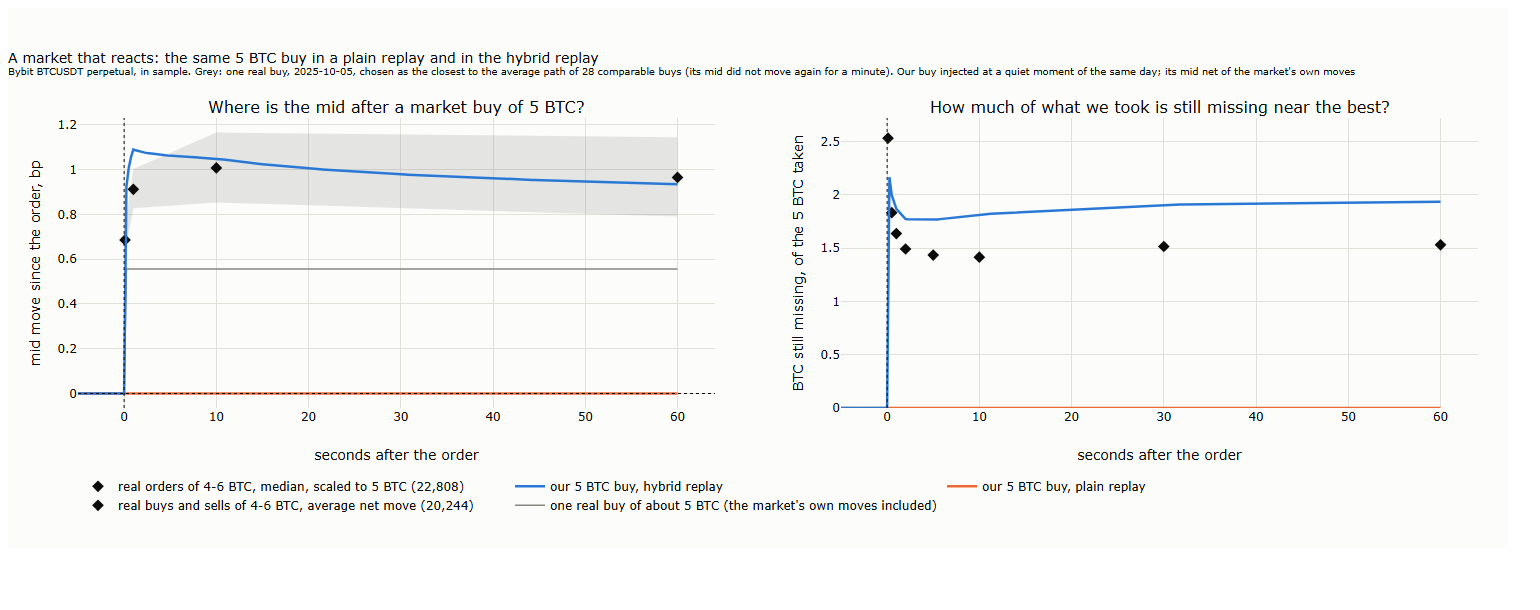

seconds,"hybrid mid, bp","real orders of 4-6 BTC, bp",hybrid: BTC still missing,real: BTC still missing
i64,f64,f64,f64,f64
1,1.09,0.91,1.87,1.64
10,1.05,1.01,1.82,1.42
60,0.93,0.97,1.94,1.53


real buy: 2025-10-05 S = 5.805 BTC, one of 28 comparable buys


In [2]:
run("l22_key.py", *(["--run"] if RUN_ALL else []))
pictures("22_key")
K = result("key.json"); g = np.array(K["grid"]); at = lambda arr, t: arr[int(np.argmin(abs(g - t)))]
display(pl.DataFrame({"seconds": [1, 10, 60], "hybrid mid, bp": [round(at(K["inj"]["hybrid"]["mid"], t * 1000), 2) for t in (1, 10, 60)],
                      "real orders of 4-6 BTC, bp": [round(v, 2) for v in K["avg"]["mean"][1:4]],
                      "hybrid: BTC still missing": [round(at(K["inj"]["hybrid"]["depth"], t * 1000), 2) for t in (1, 10, 60)],
                      "real: BTC still missing": [round(K["real_missing"]["missing"][i], 2) for i in (2, 5, 7)]}))
print("real buy:", K["day"], "S =", round(K["S"], 3), "BTC, one of", K["n_cand"], "comparable buys")

## 2. The laboratory market

First the hand-case checks of `scripts/checks/test_sim.py`: the book's matching, every trader's bookkeeping, the run rule, the clock measures, the scalper, and the hybrid replay's walk, depletion, refill, shift and parent orders. Then the ten steps: steps 1 and 2 are simulated each time (seconds); steps 3 to 10 are redrawn from their saved results, or simulated again with `RUN_SIM`. Step 6, the scalper's echo, belongs to the lecture on trading styles.

hand cases hold
noise run: no crossed book, 1469 trades, 685 orders resting
market maker: position -0.373 matches its 386 fills
sniper: position -0.5 matches its 45 fills
twap: 15 parents, 143 slices; run rule holds on a hand case
marks: flow and spread hold on a hand case
fake marks: compared with their minute's quiet seconds
scalper: position 0.0 matches its fills; 36 round trips
hybrid replay: walk, depletion, refill and shift hold on hand cases
hybrid replay: parent orders take the impact of their cumulative size
  (2 s)


l22_sim_charts.py : 6 s


l22_sim_step2.py : 19 s


l22_sim_step3.py : 4 s


l22_sim_step4.py : 4 s


l22_sim_step5.py : 4 s


l22_sim_step7.py : 4 s


l22_sim_step8.py : 3 s


l22_sim_step9.py : 3 s


l22_sim_step10.py : 3 s


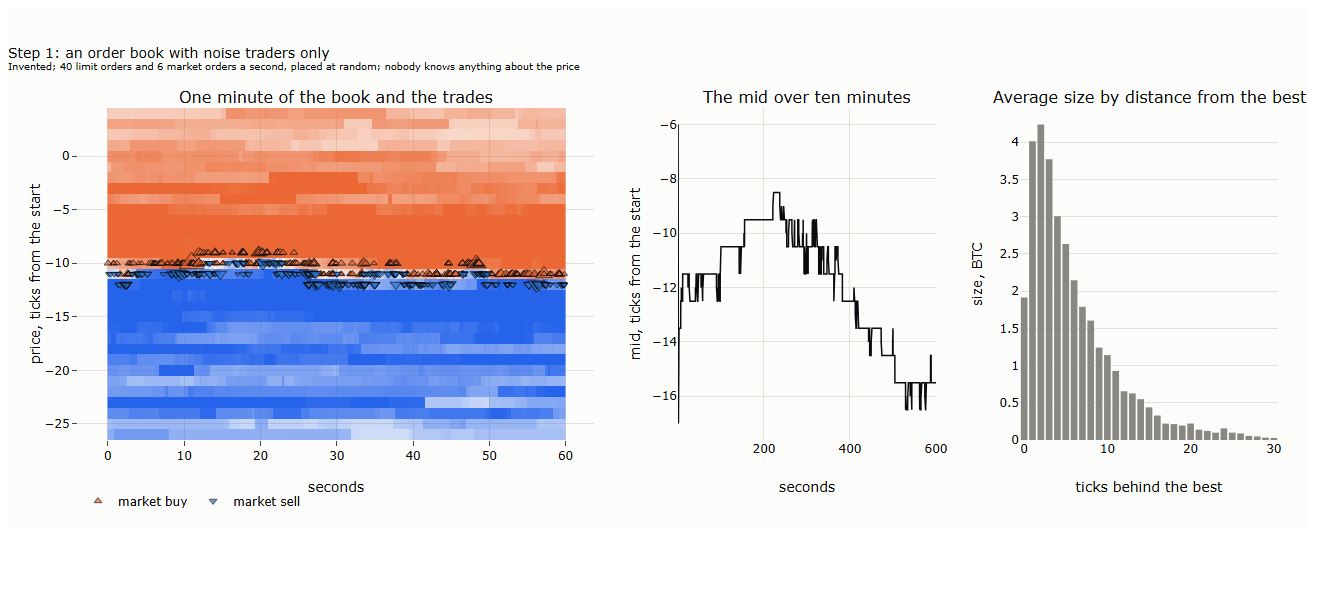

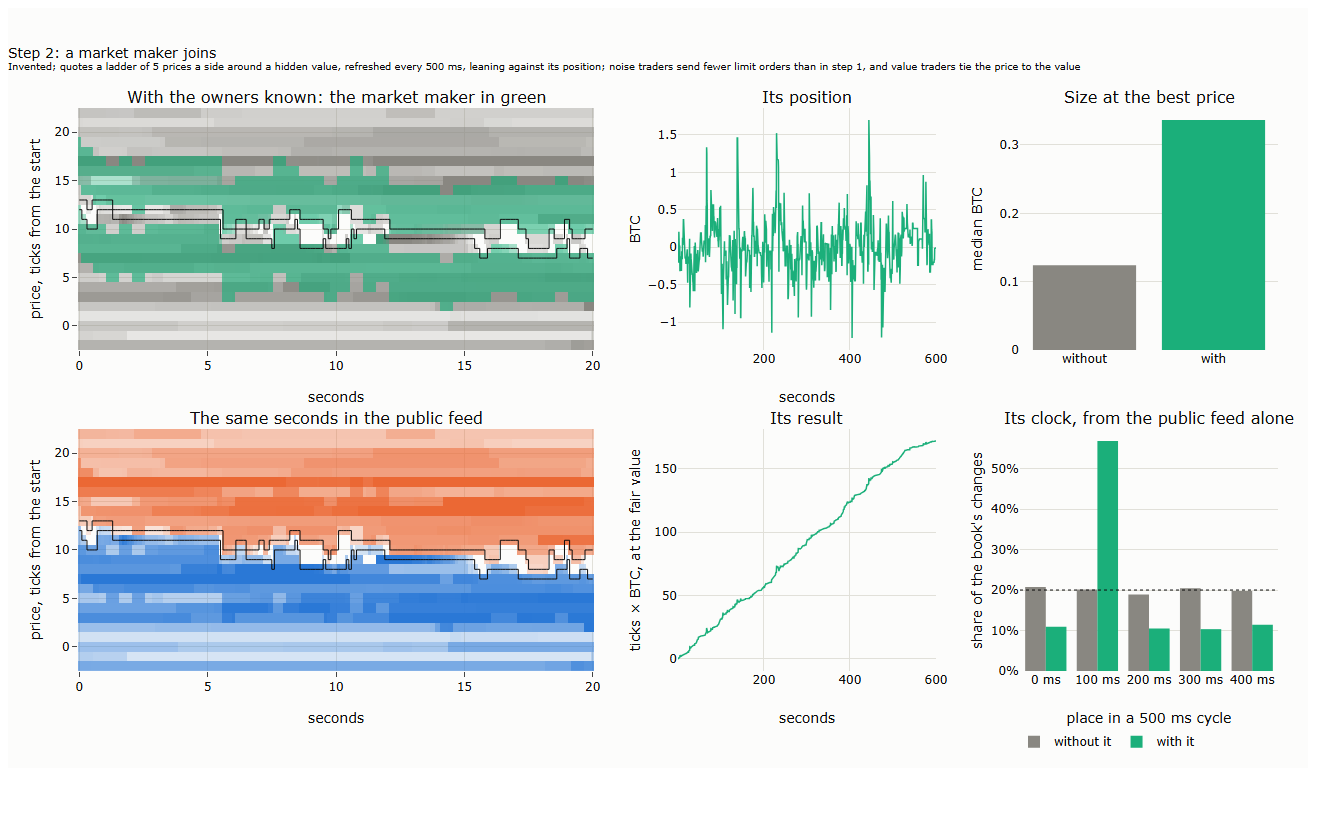

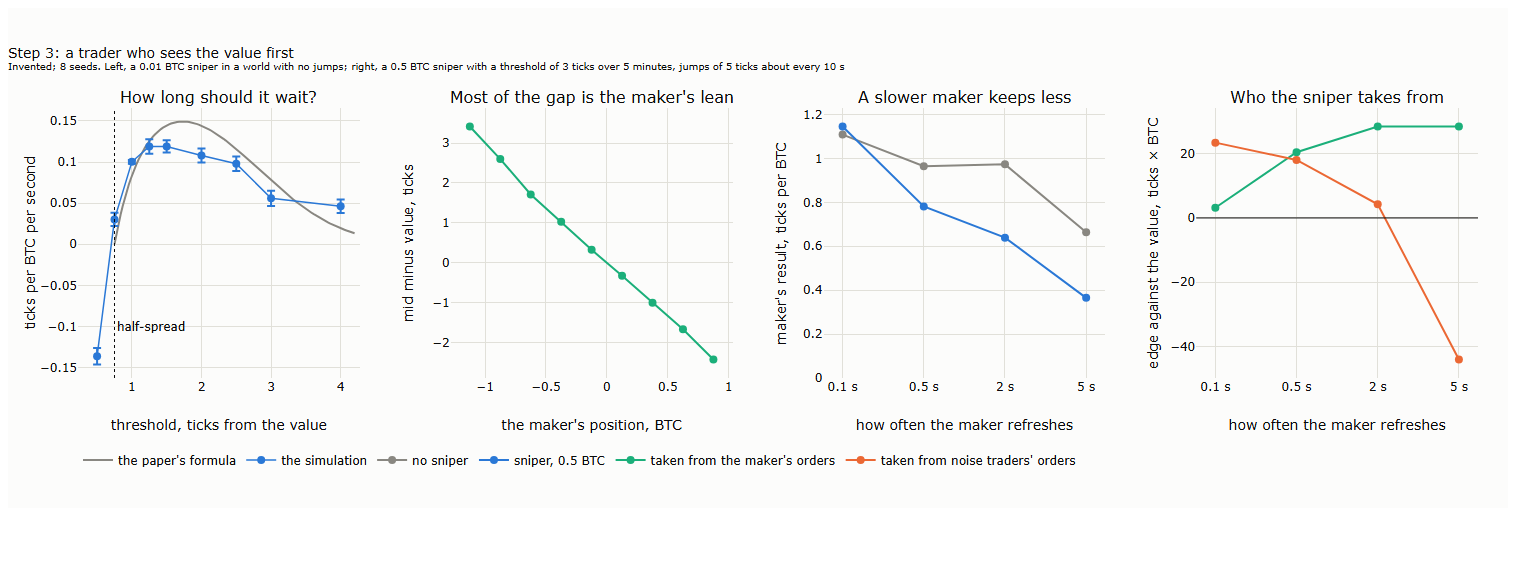

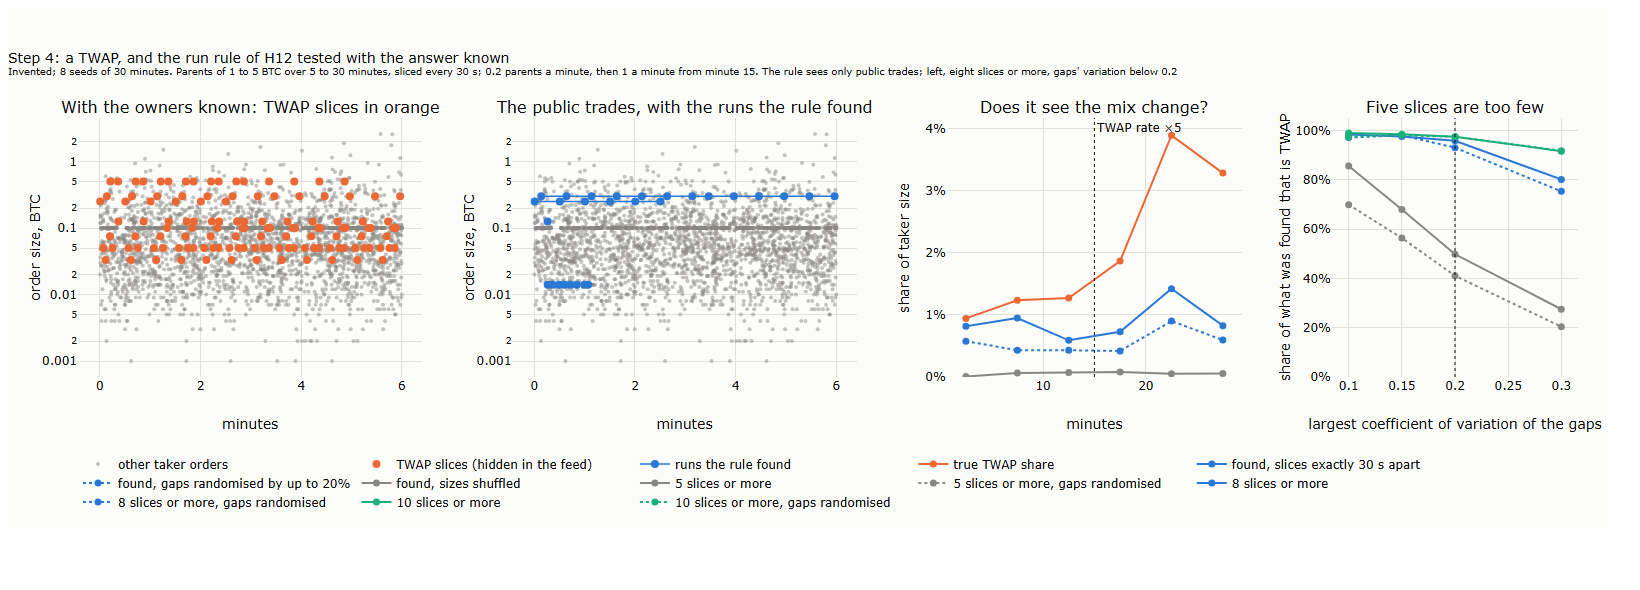

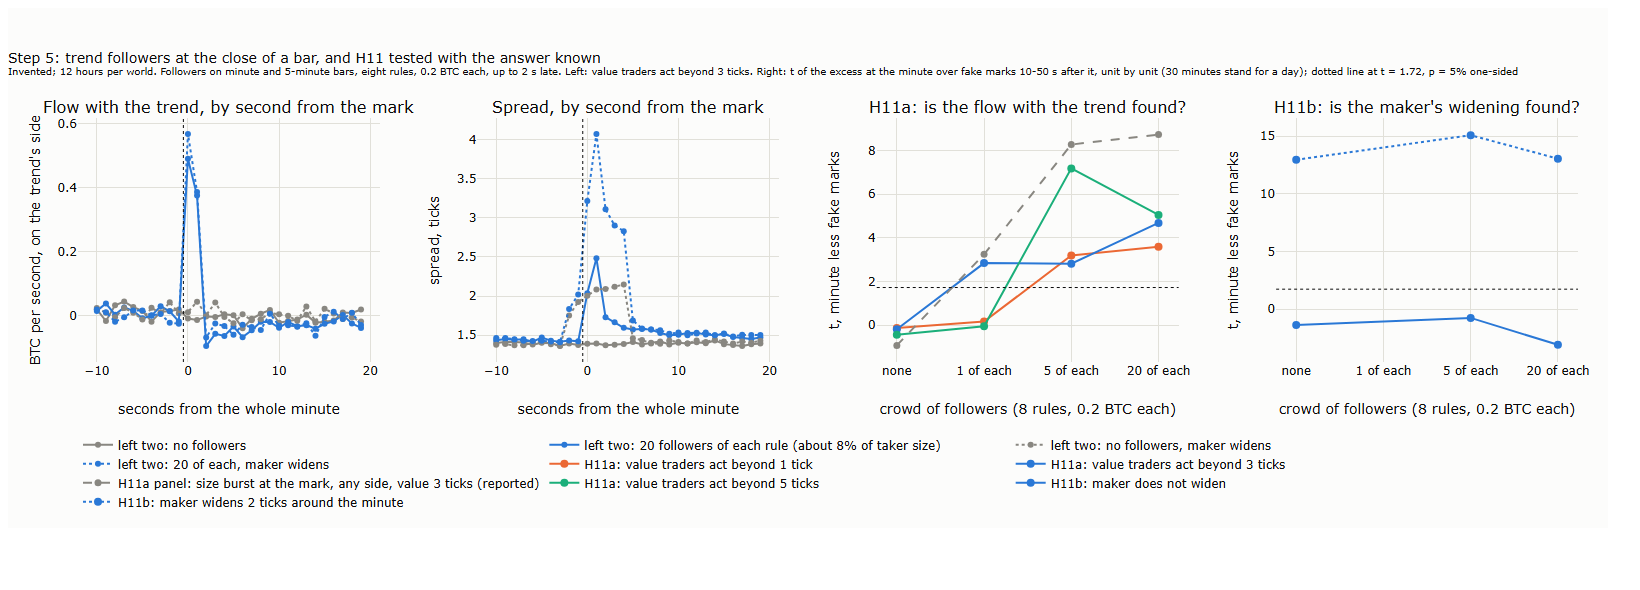

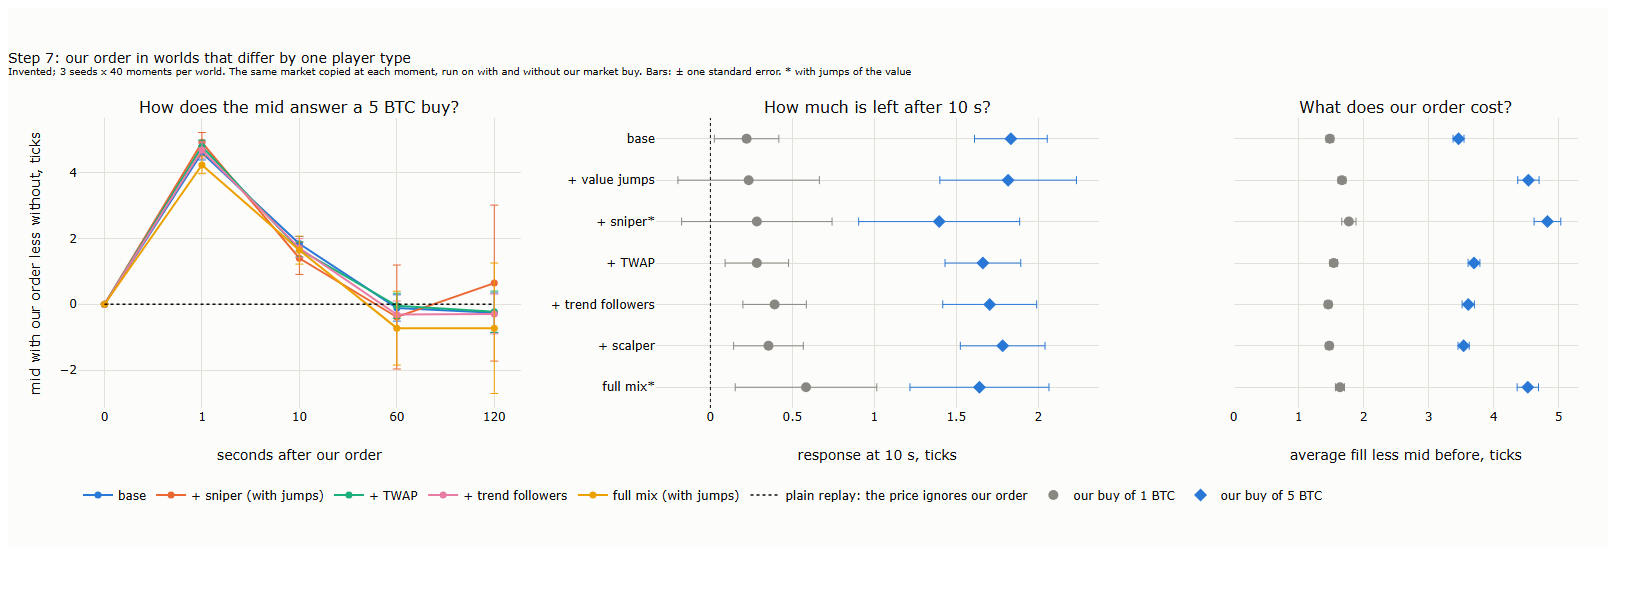

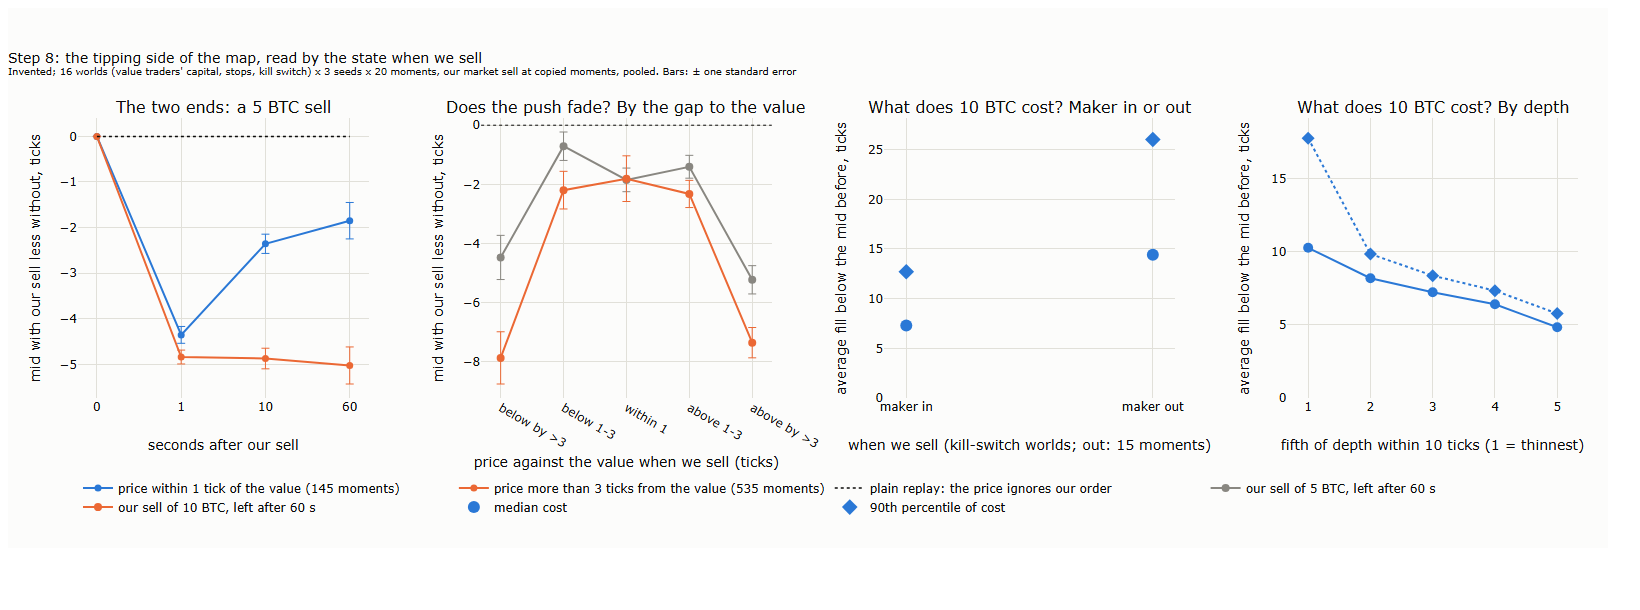

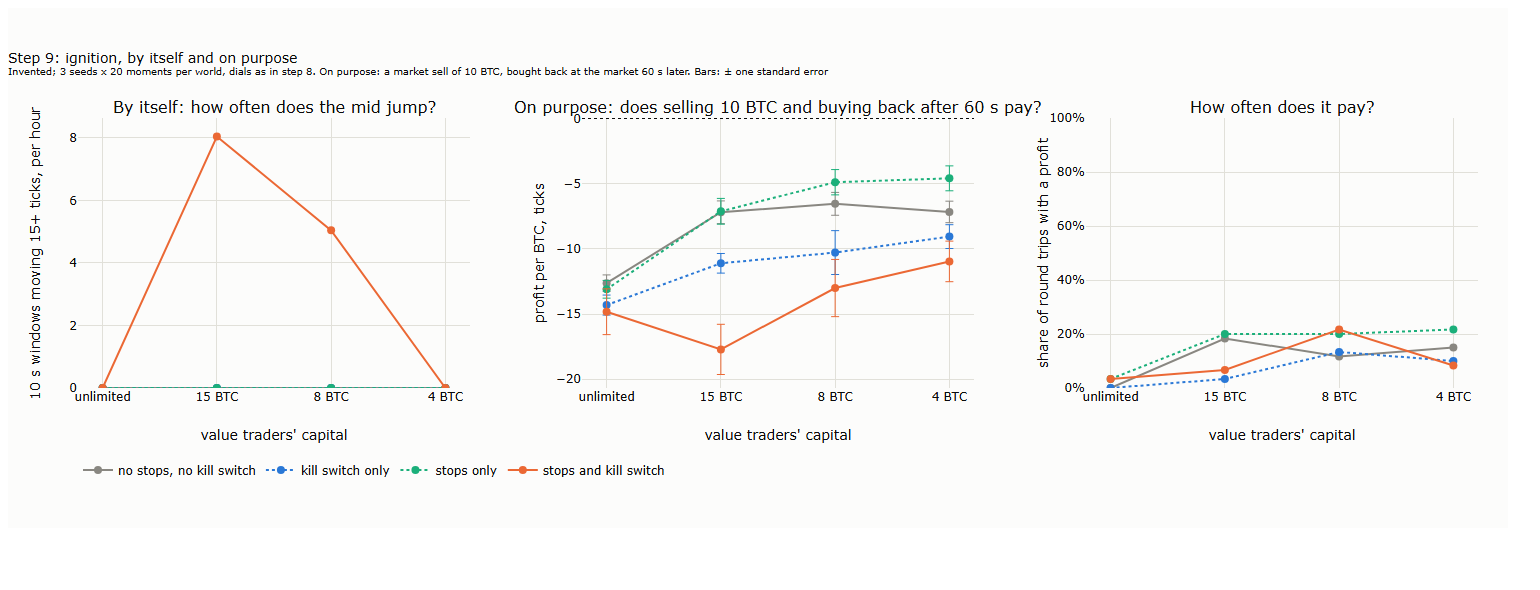

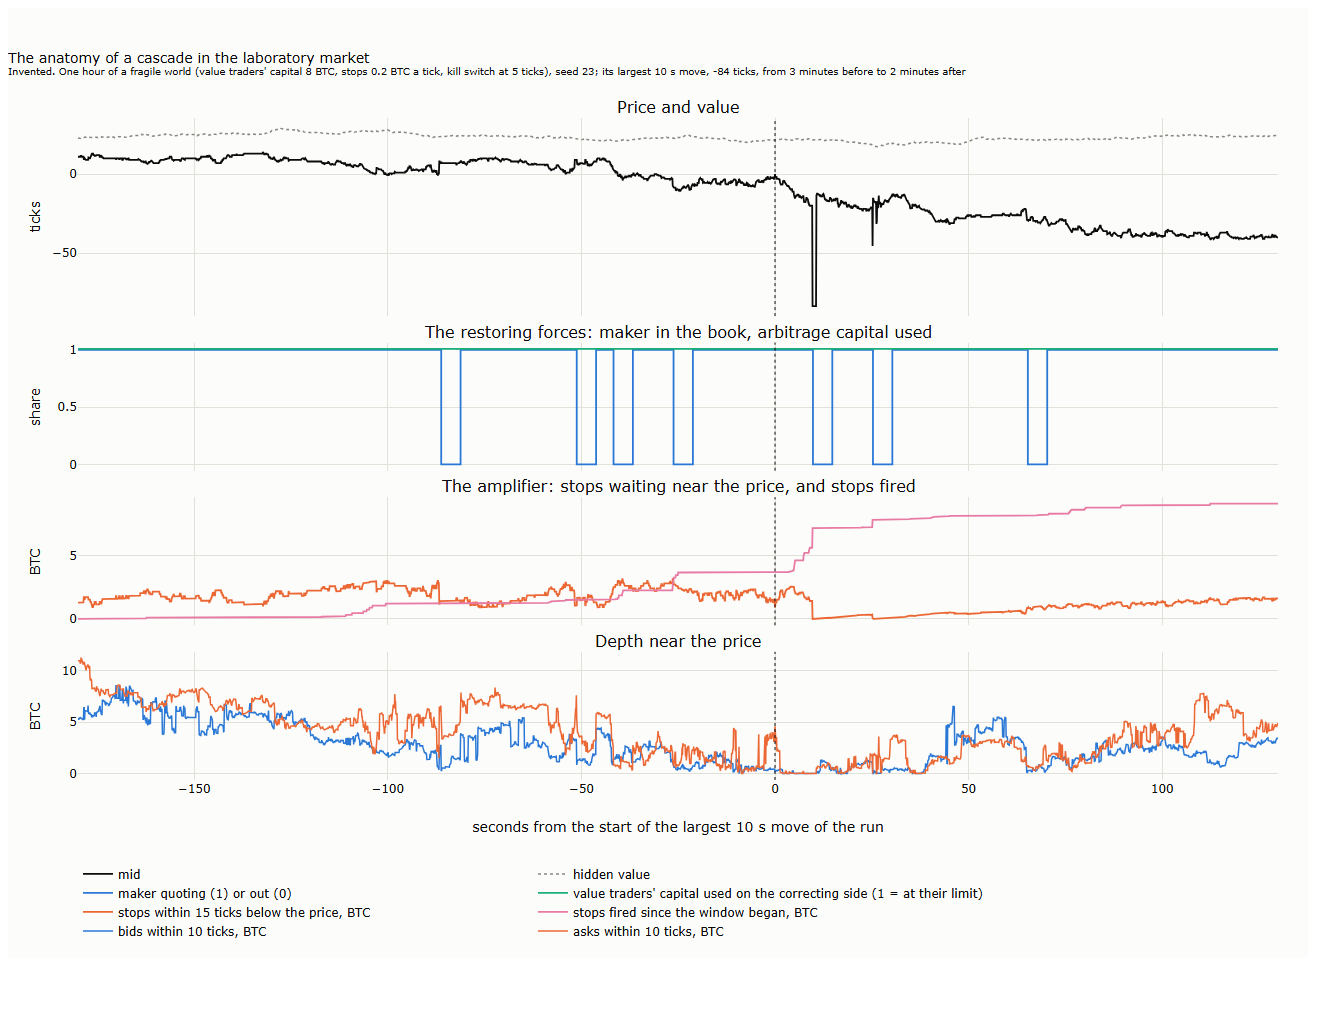

In [3]:
t0 = time.time(); p = subprocess.run([sys.executable, "-I", str(SCRIPTS / "checks" / "test_sim.py")], capture_output=True, text=True, encoding="utf-8")
print(p.stdout, p.stderr[-2000:] if p.returncode else "", f"({time.time() - t0:.0f} s)")
run("l22_sim_charts.py"); run("l22_sim_step2.py")
for s in ("l22_sim_step3.py", "l22_sim_step4.py", "l22_sim_step5.py", "l22_sim_step7.py", "l22_sim_step8.py", "l22_sim_step9.py", "l22_sim_step10.py"): run(s, *(["--run"] if RUN_SIM else []))
pictures("22_sim_step1", "22_sim_step2", "22_sim_step3", "22_sim_step4", "22_sim_step5", "22_sim_step7", "22_sim_step8", "22_sim_step9", "22_sim_step10")

The numbers of §2.2: the state when our 10 BTC sell arrives, in the 960 moments of step 8, and the stages of the cascade of step 10 (§2.3).

In [4]:
S8 = result("sim_step8.json"); M = [dict(m, w=k) for k, v in S8.items() for m in v["moments"]]
gap = np.array([m["gap"] for m in M]); r10 = np.array([m["r10"][2] for m in M]); c10 = np.array([m["c10"] for m in M], float)
out = np.array([m["maker_out"] for m in M]); kill = np.array([m["w"].endswith("|5") for m in M])
display(pl.DataFrame({"state": ["price within 3 ticks of the value", "price more than 3 ticks from the value"], "moments": [int((abs(gap) <= 3).sum()), int((abs(gap) > 3).sum())],
                      "10 BTC left after 60 s, ticks": [round(r10[abs(gap) <= 3].mean(), 2), round(r10[abs(gap) > 3].mean(), 2)]}))
display(pl.DataFrame({"maker": ["in", "out"], "moments": [int((kill & ~out).sum()), int((kill & out).sum())],
                      "median cost, ticks": [round(np.nanmedian(c10[kill & ~out]), 1), round(np.nanmedian(c10[kill & out]), 1)],
                      "90th percentile, ticks": [round(np.nanpercentile(c10[kill & ~out], 90), 1), round(np.nanpercentile(c10[kill & out], 90), 1)]}))
R = result("sim_step10.json"); t = np.array(R["t"]); i0 = R["k"] - max(R["k"] - 1800, 0); s = (t - t[i0]) / 1000; mid = np.array(R["mid"]); base = mid[i0]
rows = []
for a, b, nm in ((-180, -90, "loading"), (-90, 0, "flickering"), (0, 15, "chain reaction"), (15, 40, "exhaustion"), (40, 130, "aftermath")):
    w = (s >= a) & (s < b)
    rows.append((nm, round(float(np.median(mid[w] - base)), 1), round(float(np.median(np.array(R["value"])[w] - mid[w])), 1), round(float(np.array(R["maker_out"])[w].mean()), 2),
                 round(float(np.median(np.array(R["stops_below"])[w])), 1), round(float(np.median(np.array(R["depth_bid"])[w])), 1), round(float(np.median(np.array(R["depth_ask"])[w])), 1)))
display(pl.DataFrame(rows, schema=["stage", "mid, ticks", "value above mid, ticks", "maker out", "stops below, BTC", "bids near, BTC", "asks near, BTC"], orient="row"))

state,moments,"10 BTC left after 60 s, ticks"
str,i64,f64
"""price within 3 ticks of the value""",425,-2.11
"""price more than 3 ticks from the value""",535,-7.41


maker,moments,"median cost, ticks","90th percentile, ticks"
str,i64,f64,f64
"""in""",465,7.3,12.7
"""out""",15,14.4,26.0


stage,"mid, ticks","value above mid, ticks",maker out,"stops below, BTC","bids near, BTC","asks near, BTC"
str,f64,f64,f64,f64,f64,f64
"""loading""",9.0,16.9,0.0,1.9,5.2,6.4
"""flickering""",2.0,20.7,0.22,1.9,1.7,3.3
"""chain reaction""",-13.8,35.8,0.33,1.6,0.0,0.1
"""exhaustion""",-19.5,39.4,0.2,0.2,0.4,0.7
"""aftermath""",-36.0,59.2,0.06,1.1,2.4,3.1


## 3. The reaction on our data, in sample

`l22_orders.py` builds, day by day, the table of real orders and of control moments; `l22_book.py` passes over the book once for quote pulls and the refill after every order of 1 BTC or more (the order table is rebuilt after it, to carry the pulls). `l22_s3_response.py` and `l22_s3_refill.py` estimate the layers on the 20 days in sample. With `RUN_CHECK` one day is rebuilt and compared with the lecture's values; with `RUN_ALL` every day.

l22_s3_response.py : 3 s


l22_s3_refill.py : 3 s


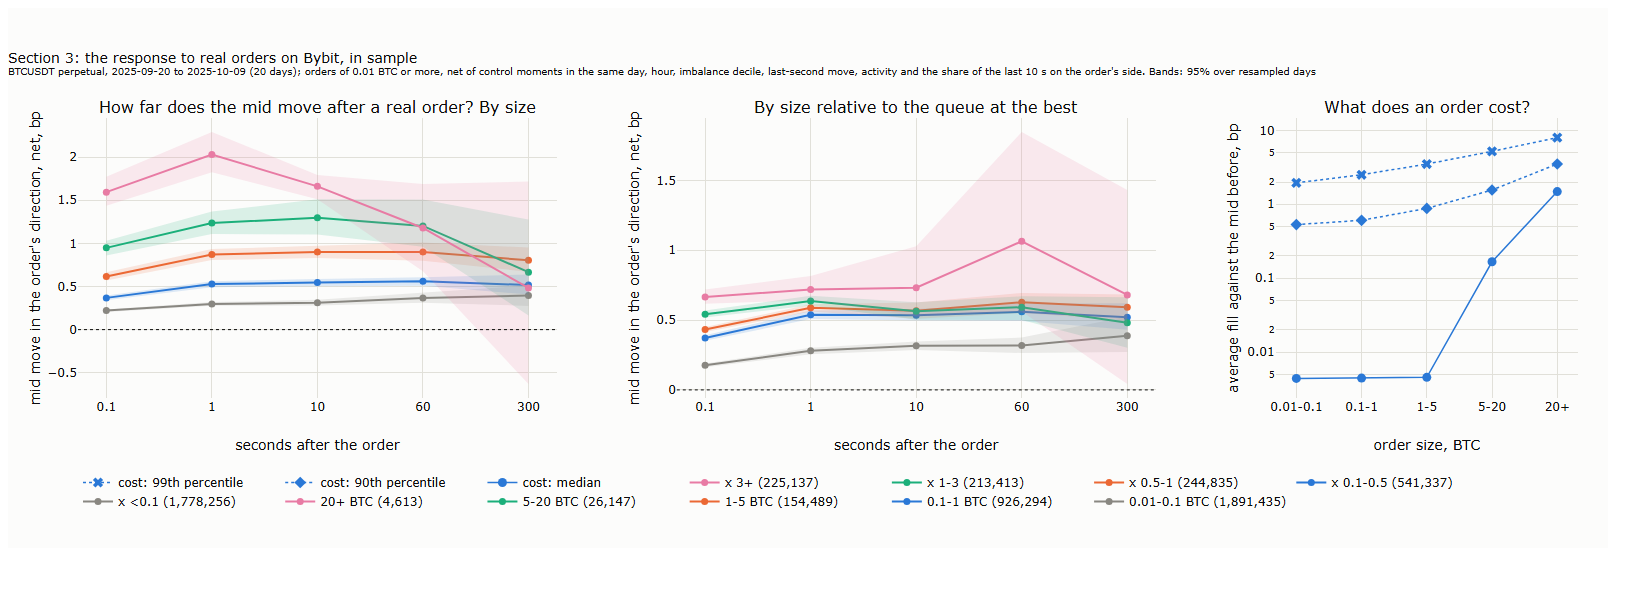

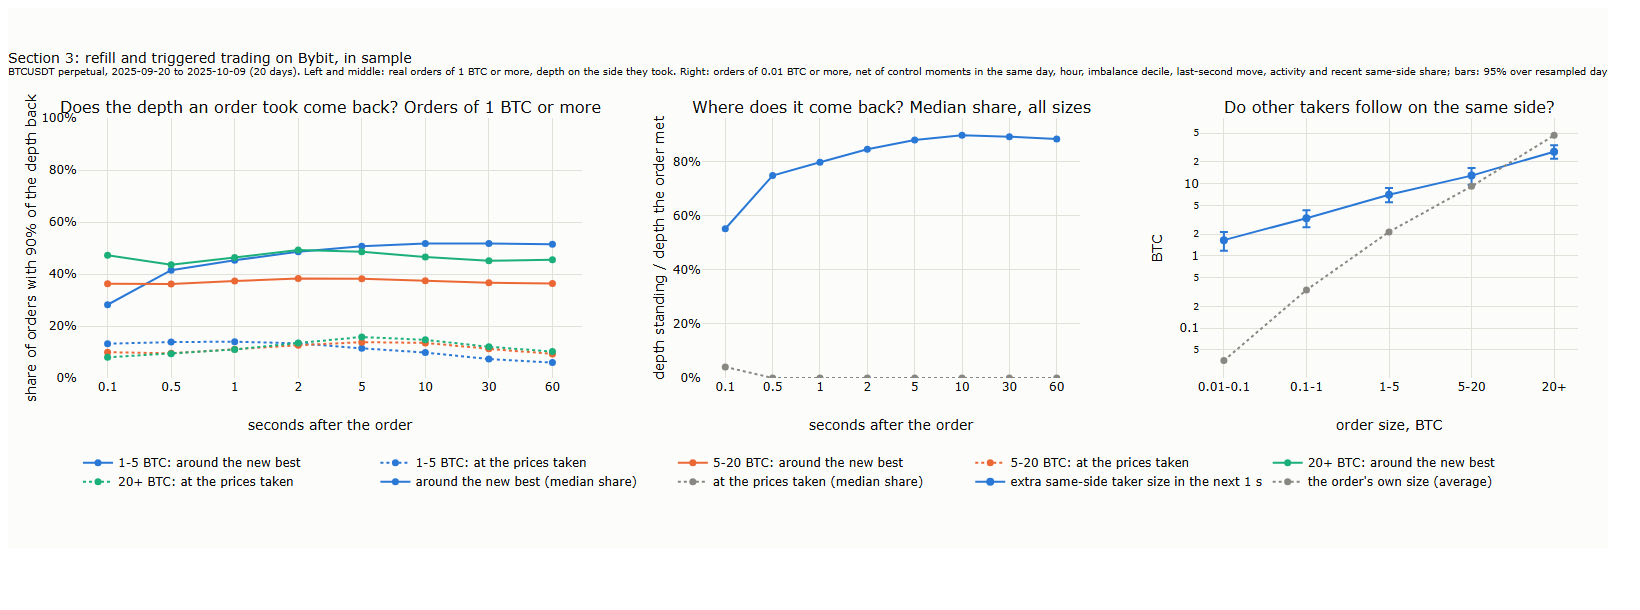

"size, BTC",orders,"net move 1 s, bp",10 s,300 s,"extra same-side size in 1 s, BTC"
str,i64,f64,f64,f64,f64
"""0.01-0.1""",1891435,0.3,0.31,0.4,1.65
"""0.1-1""",926294,0.53,0.55,0.52,3.32
"""1-5""",154489,0.87,0.9,0.8,7.01
"""5-20""",26147,1.24,1.3,0.67,12.89
"""20+""",4613,2.03,1.66,0.48,27.62


"size, BTC",orders,"median cost, bp",90th,99th
str,i64,f64,f64,f64
"""0.01-0.1""",1891435,0.004,0.531,1.95
"""0.1-1""",926294,0.004,0.607,2.507
"""1-5""",154489,0.005,0.879,3.504
"""5-20""",26147,0.167,1.56,5.194
"""20+""",4613,1.486,3.506,7.973


fitted R = c S^delta in sample (bp): {100: (0.522, 0.276), 1000: (0.712, 0.265), 10000: (0.714, 0.239), 60000: (0.702, 0.178), 300000: (0.544, 0.043)}


In [5]:
def build(d):
    state(d); run("l22_orders.py", d); run("l22_book.py", d); run("l22_orders.py", d)

if RUN_ALL:
    for d in DAYS:
        if not (L.OUT / "refill" / f"{d}.parquet").exists(): build(d)
elif RUN_CHECK:
    build(CHECK_DAY); run("l22_check_day.py", CHECK_DAY)
    a, b = json.loads((SHIPPED / f"check_{CHECK_DAY}.json").read_text()), result(f"check_{CHECK_DAY}.json")
    display(pl.DataFrame([(k, float(a[k]), float(b[k])) for k in a], schema=["measure", "lecture", "this run"], orient="row"))
for s in ("l22_s3_response.py", "l22_s3_refill.py"): run(s, *(["--run"] if RUN_ALL else []))
pictures("22_s3_response", "22_s3_refill")
Q = result("s3_response.json")
display(pl.DataFrame([(k.split("|")[1], v["n"], *[round(x, 2) for x in (v["mean"][1], v["mean"][2], v["mean"][4])], round(v["flow"], 2)) for k, v in Q["curves"].items() if k.startswith("cls|")],
                     schema=["size, BTC", "orders", "net move 1 s, bp", "10 s", "300 s", "extra same-side size in 1 s, BTC"], orient="row"))
display(pl.DataFrame([(k, v["n"], round(v["p50"], 3), round(v["p90"], 3), round(v["p99"], 3)) for k, v in Q["cost"].items()], schema=["size, BTC", "orders", "median cost, bp", "90th", "99th"], orient="row"))
import l22_hybrid as H
print("fitted R = c S^delta in sample (bp):", {t: tuple(round(x, 3) for x in v) for t, v in H.fit_response(RES / "s3_response.json").items()})

## 4. Does the hybrid replay tell the truth?

`l22_s4_tests.py` runs H1 to H6, H9 and H20 on the 24 days out of sample, `l22_s4_replay.py` the runs of orders of H7 (and, with `--parent`, the follow-up), `l22_s4_h8.py` the round trip of H8, and `l22_s4_charts.py` draws the figures of §4 and §5. The table applies Benjamini-Hochberg at 5% over the ten primary tests, as in the lecture.

l22_s4_charts.py : 5 s


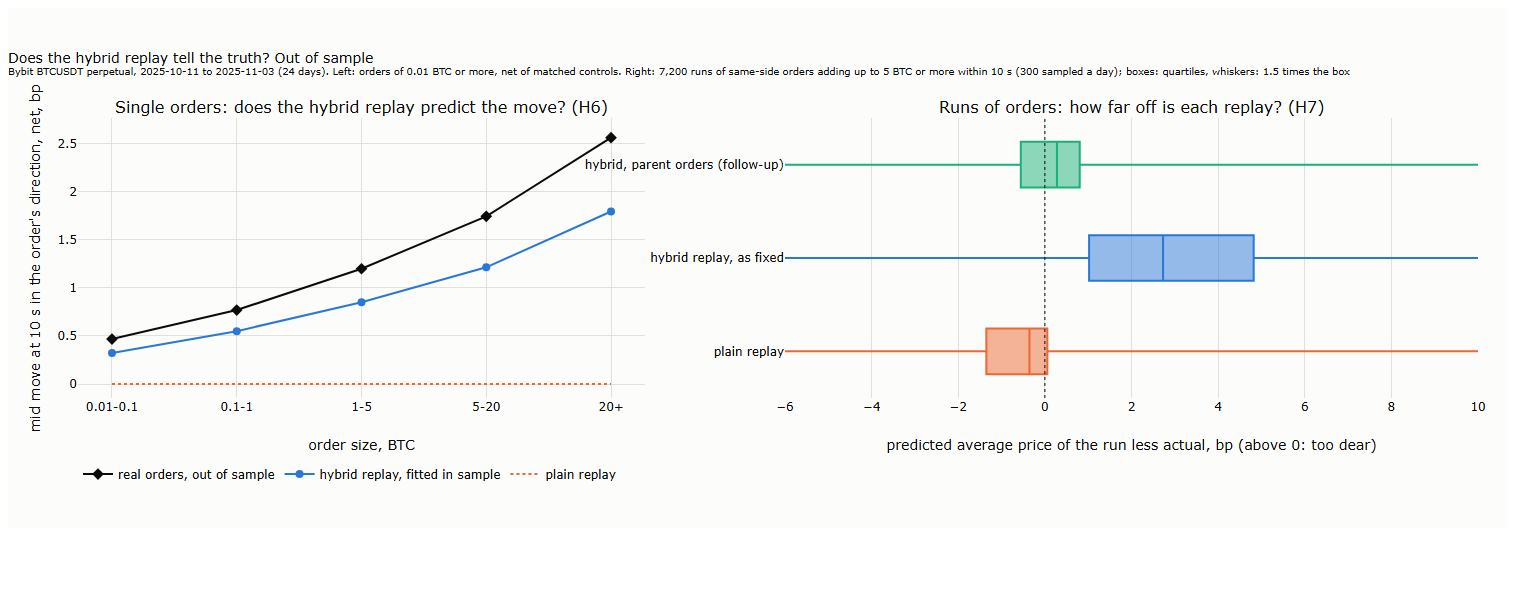

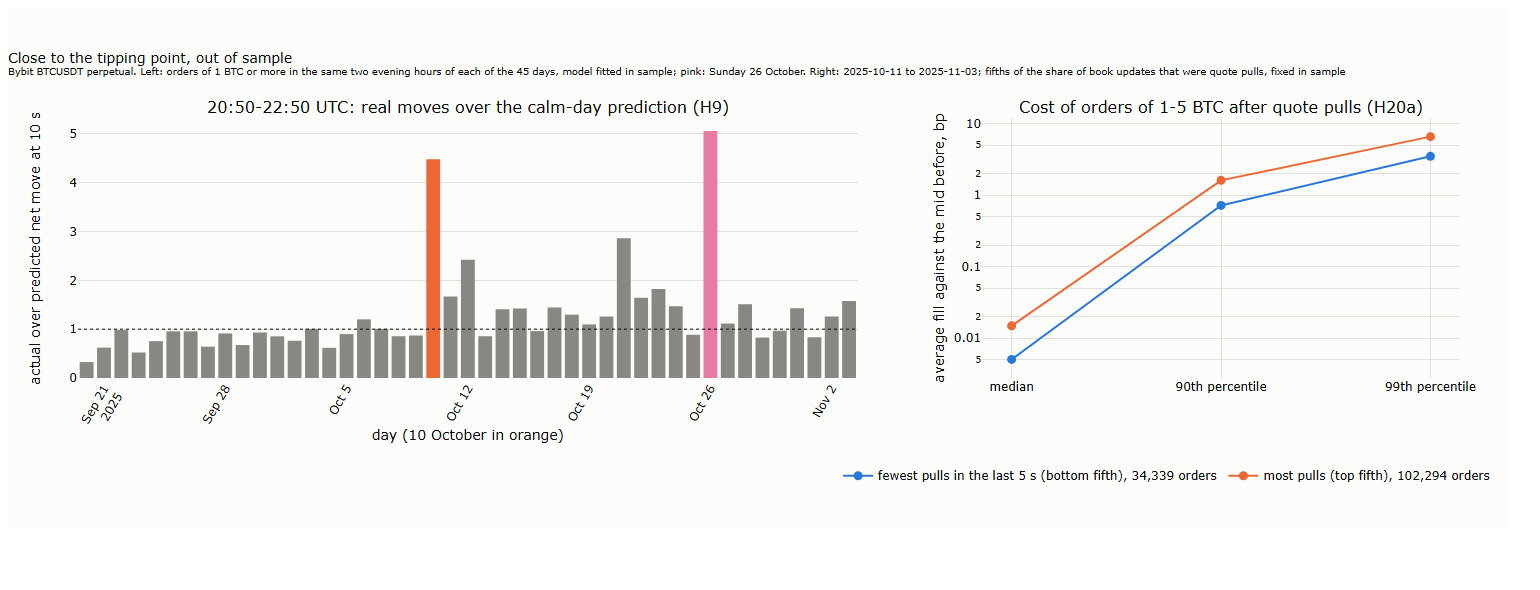

hypothesis,statistic (H9: rank),p,corrected,verdict
str,f64,f64,f64,str
"""H1""",0.278,0.0005,0.001,"""holds"""
"""H2""",0.235,0.0005,0.001,"""holds"""
"""H3""",0.379,0.0375,0.0625,"""fails"""
"""H4""",9.986,0.0005,0.001,"""holds"""
"""H5""",-0.09,1.0,1.0,"""fails"""
"""H6""",1.374,0.0005,0.001,"""holds"""
"""H7""",-2.196,1.0,1.0,"""fails"""
"""H9""",2.0,0.0444,0.0635,"""fails"""
"""H20a""",0.896,0.0005,0.001,"""holds"""


H6 actual over predicted: 1.33
H7 runs: 7200 | mean |error| plain 1.29 hybrid 3.48 | parent-order follow-up 1.23 bias 0.13
H8: {'p_violated': 0.995, 'mean_diff_usdt': -0.598, 'share_bid_touched': 0.174, 'share_diff_positive': 0.893, 'mean_gain_bp': 0.25, 'median_diff_usdt': 0.003} | trade-through: -1.808


In [6]:
if RUN_ALL:
    run("l22_s4_tests.py", "--run"); run("l22_s4_replay.py", "--run"); run("l22_s4_replay.py", "--run", "--parent"); run("l22_s4_h8.py", "--run"); run("l22_s4_charts.py", "--run")
else: run("l22_s4_charts.py")
pictures("22_s4_replay", "22_s5_fragile")
T = result("s4_tests.json"); P = result("s4_replay.json"); PP = result("s4_replay_parent.json")
ps = {k: v["p"] for k, v in T["tests"].items()}; ps["H7"] = P["H7"]["p"]; fam = ["H1", "H2", "H3", "H4", "H5", "H6", "H7", "H9", "H20a", "H20b"]
p = np.array([max(ps[k], 1 / 2001) for k in fam]); o = np.argsort(p); m = len(p); q = np.empty(m); q[o] = np.minimum.accumulate((p[o] * m / np.arange(1, m + 1))[::-1])[::-1]
stat = {k: T["tests"][k].get("stat", T["tests"][k].get("rank")) for k in T["tests"]}; stat["H7"] = P["H7"]["stat"]   # H9's statistic is a rank among the days
display(pl.DataFrame({"hypothesis": fam, "statistic (H9: rank)": [round(float(stat[k]), 3) for k in fam], "p": [round(float(x), 4) for x in p], "corrected": [round(float(min(x, 1)), 4) for x in q],
                      "verdict": ["holds" if x <= 0.05 else "fails" for x in q]}))
print("H6 actual over predicted:", round(T["tests"]["H6"]["actual_over_predicted"], 2))
print("H7 runs:", P["runs"], "| mean |error| plain", round(P["H7"]["mae_plain"], 2), "hybrid", round(P["H7"]["mae_hybrid"], 2), "| parent-order follow-up", round(PP["H7"]["mae_hybrid"], 2), "bias", round(PP["H7"]["bias_hybrid"], 2))
H8 = result("s4_h8.json"); print("H8:", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in H8["H8"].items() if k != "ci"}, "| trade-through:", H8.get("sensitivity_trade_through", {}).get("mean_diff_usdt"))

## 5. Close to the tipping point

The numbers of §5: the cost tail after quote pulls (H20a), 10 October against the other evenings (H9), and the evenings before and after the cascade.

In [7]:
a = T["tests"]["H20a"]
display(pl.DataFrame([(g, a[g]["n"], round(a[g]["p50"], 3), round(a[g]["p90"], 2), round(a[g]["p99"], 2)) for g in ("bottom", "top")], schema=["fifth of quote pulls", "orders", "median cost, bp", "90th", "99th"], orient="row"))
W = T["h9_days"]; r = sorted(W, key=lambda d: -W[d]["ratio_S"])
print("H9: 10 October ranks", r.index("2025-10-10") + 1, "of", len(r), "| top three:", [(d, round(W[d]["ratio_S"], 2), W[d]["n"]) for d in r[:3]])
pre = [W[d]["ratio_S"] for d in W if d < "2025-10-10"]; post = [W[d]["ratio_S"] for d in W if d > "2025-10-10"]
print(f"evening ratio, median: before {np.median(pre):.2f}, after {np.median(post):.2f}; share of evenings above 1 after: {np.mean(np.array(post) > 1):.2f}")

fifth of quote pulls,orders,"median cost, bp",90th,99th
str,i64,f64,f64,f64
"""bottom""",34339,0.005,0.72,3.51
"""top""",102294,0.015,1.62,6.62


H9: 10 October ranks 2 of 45 | top three: [('2025-10-26', 5.06, 1807), ('2025-10-10', 4.48, 20756), ('2025-10-21', 2.86, 2300)]
evening ratio, median: before 0.86, after 1.42; share of evenings above 1 after: 0.75


## 6. A test of your own: why runs cannot be added up

Exercise 1 of §7.2. With $R = c\,S^{\delta}$, a parent order of size $S$ split into $n$ equal slices, each charged its own impact, adds up to $n^{1-\delta}$ times the impact of the whole. The cell computes the factor for the exponent fitted in sample and compares the two charges for a run of 5 BTC in ten slices.

In [8]:
c, d = H.fit_response(RES / "s3_response.json")[10_000]; n, S = 10, 5.0
print(f"delta at 10 s: {d:.3f} | n^(1-delta) for n = {n}: {n ** (1 - d):.2f}")
print(f"one order of {S:g} BTC: {c * S ** d:.2f} bp | ten slices of {S / n:g} BTC, added up: {n * c * (S / n) ** d:.2f} bp")

delta at 10 s: 0.239 | n^(1-delta) for n = 10: 5.76
one order of 5 BTC: 1.05 bp | ten slices of 0.5 BTC, added up: 6.05 bp
